In [1]:
import os
import glob

os.environ['YOLO_VERBOSE'] = 'False'

import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline

In [13]:
WEIGHTS_PTH = "results/baseline_2_3m/weights/best.pt"

BASE_PTH = "/home/klymy/data/people_detection/baseline_10sec"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

VAL_IMGS_PTH = os.path.join(BASE_PTH, "images/val")
HOLDOUT_IMGS_PTH = os.path.join(BASE_PTH, "images/holdout")
ALGOTEST_IMGS_PTH = os.path.join(BASE_PTH, "images/algotest")

In [14]:
CONF_TH = 0.0
IOU_TH = 0.6

In [15]:
def print_metrics(metrics, conf_th=0, draw=True):
    data = [
        {
            "task": "box",
            "F1": metrics.box.f1[0],
            "P": metrics.box.p[0],
            "R": metrics.box.r[0],
            "MAP@50": metrics.box.map50,
        },
        {
            "task": "pose",
            "F1": metrics.pose.f1[0],
            "P": metrics.pose.p[0],
            "R": metrics.pose.r[0],
            "MAP@50": metrics.pose.map50,
        }
    ]
    print(pd.DataFrame(data))

    if not draw:
        return
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    x = np.linspace(conf_th, 1, num=len(metrics.box.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.box.f1_curve[0], label="F1")
    plt.plot(x, metrics.box.r_curve[0], label="R")
    plt.plot(x, metrics.box.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("BOX")

    plt.subplot(1, 2, 2)
    x = np.linspace(conf_th, 1, num=len(metrics.pose.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.pose.f1_curve[0], label="F1")
    plt.plot(x, metrics.pose.r_curve[0], label="R")
    plt.plot(x, metrics.pose.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("POSE");

## Default Validation

### Hold-out set

   task    F1     P     R  MAP@50
0   box 0.559 0.583 0.536   0.442
1  pose 0.871 0.915 0.831   0.922


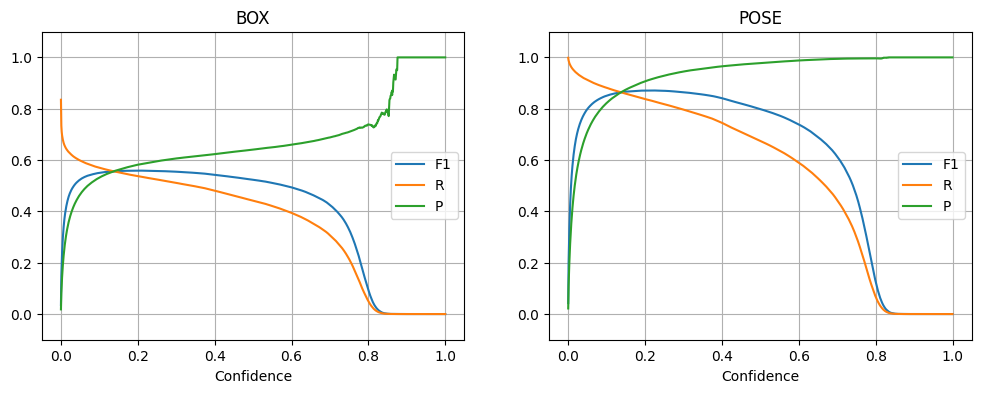

In [16]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=HOLDOUT_PTH,
    task="pose",
    device=[2],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

### Algotest set

   task    F1     P     R  MAP@50
0   box 0.828 0.878 0.784   0.843
1  pose 0.864 0.912 0.820   0.903


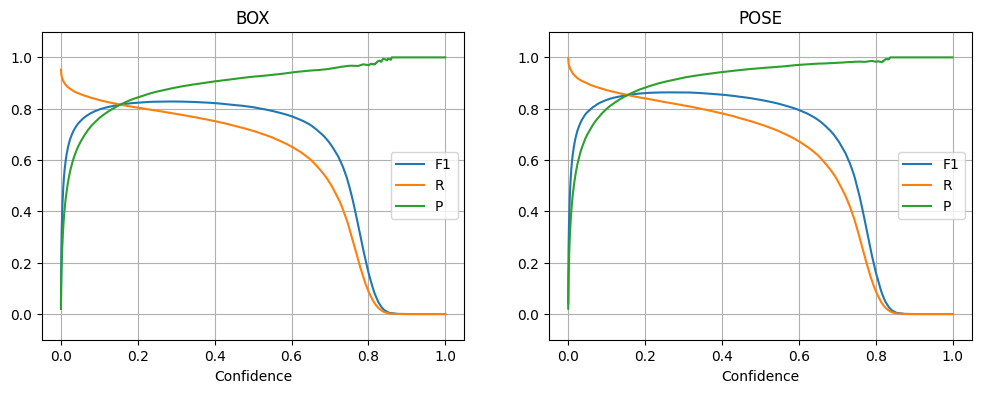

In [17]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=ALGOTEST_PTH,
    task="pose",
    device=[2],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

## CONF TH

In [12]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.51, 0.05):
    metrics = model.val(
        data=VAL_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.647 0.752 0.567   0.671
1  pose 0.799 0.886 0.727   0.835

0.25 :
   task    F1     P     R  MAP@50
0   box 0.647 0.752 0.567   0.672
1  pose 0.799 0.903 0.716   0.832

0.3 :
   task    F1     P     R  MAP@50
0   box 0.647 0.750 0.569   0.673
1  pose 0.796 0.923 0.700   0.827

0.35 :
   task    F1     P     R  MAP@50
0   box 0.646 0.766 0.558   0.672
1  pose 0.791 0.938 0.684   0.822

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.643 0.781 0.547   0.671
1  pose 0.782 0.950 0.665   0.815

0.44999999999999996 :
   task    F1     P     R  MAP@50
0   box 0.637 0.795 0.532   0.668
1  pose 0.768 0.958 0.641   0.805

0.49999999999999994 :
   task    F1     P     R  MAP@50
0   box 0.630 0.807 0.517   0.665
1  pose 0.753 0.965 0.618   0.795



In [13]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.51, 0.05):
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.558 0.582 0.537   0.505
1  pose 0.871 0.907 0.838   0.900

0.25 :
   task    F1     P     R  MAP@50
0   box 0.557 0.595 0.524   0.504
1  pose 0.870 0.929 0.818   0.892

0.3 :
   task    F1     P     R  MAP@50
0   box 0.554 0.606 0.511   0.503
1  pose 0.864 0.945 0.796   0.884

0.35 :
   task    F1     P     R  MAP@50
0   box 0.550 0.615 0.497   0.501
1  pose 0.855 0.956 0.774   0.874

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.543 0.623 0.481   0.498
1  pose 0.841 0.965 0.745   0.862

0.44999999999999996 :
   task    F1     P     R  MAP@50
0   box 0.533 0.632 0.461   0.494
1  pose 0.820 0.972 0.709   0.845

0.49999999999999994 :
   task    F1     P     R  MAP@50
0   box 0.523 0.640 0.442   0.490
1  pose 0.798 0.978 0.674   0.829



In [14]:
TUNED_CONF_TH = 0.3

## IOU THRESHOLD

In [16]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.65, 0.7]:
    metrics = model.val(
        data=VAL_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.648 0.756 0.567   0.674
1  pose 0.800 0.933 0.700   0.829

0.5 :
   task    F1     P     R  MAP@50
0   box 0.648 0.754 0.567   0.673
1  pose 0.799 0.931 0.700   0.829

0.65 :
   task    F1     P     R  MAP@50
0   box 0.646 0.746 0.569   0.672
1  pose 0.795 0.918 0.701   0.827

0.7 :
   task    F1     P     R  MAP@50
0   box 0.644 0.742 0.570   0.671
1  pose 0.793 0.912 0.701   0.825



In [17]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.65, 0.7]:
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.556 0.611 0.509   0.504
1  pose 0.868 0.955 0.795   0.885

0.5 :
   task    F1     P     R  MAP@50
0   box 0.556 0.610 0.510   0.504
1  pose 0.867 0.952 0.796   0.885

0.65 :
   task    F1     P     R  MAP@50
0   box 0.554 0.603 0.511   0.502
1  pose 0.862 0.940 0.797   0.883

0.7 :
   task    F1     P     R  MAP@50
0   box 0.552 0.598 0.512   0.501
1  pose 0.859 0.931 0.797   0.882



In [18]:
TUNED_IOU_TH = 0.5

## Visuzlization

In [ ]:
model = YOLO(WEIGHTS_PTH)

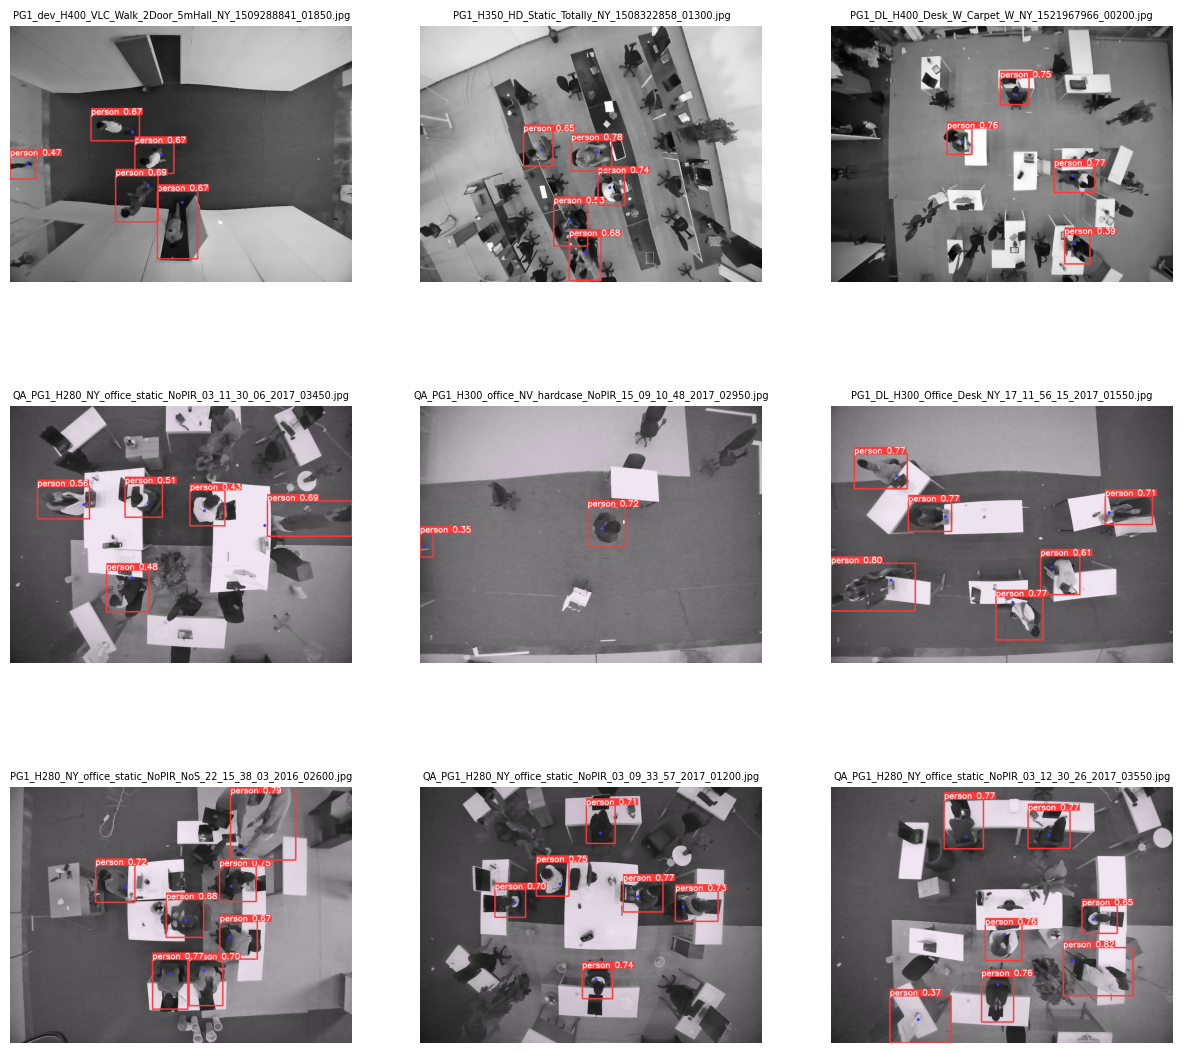

In [60]:
img_pths = glob.glob(os.path.join(VAL_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)

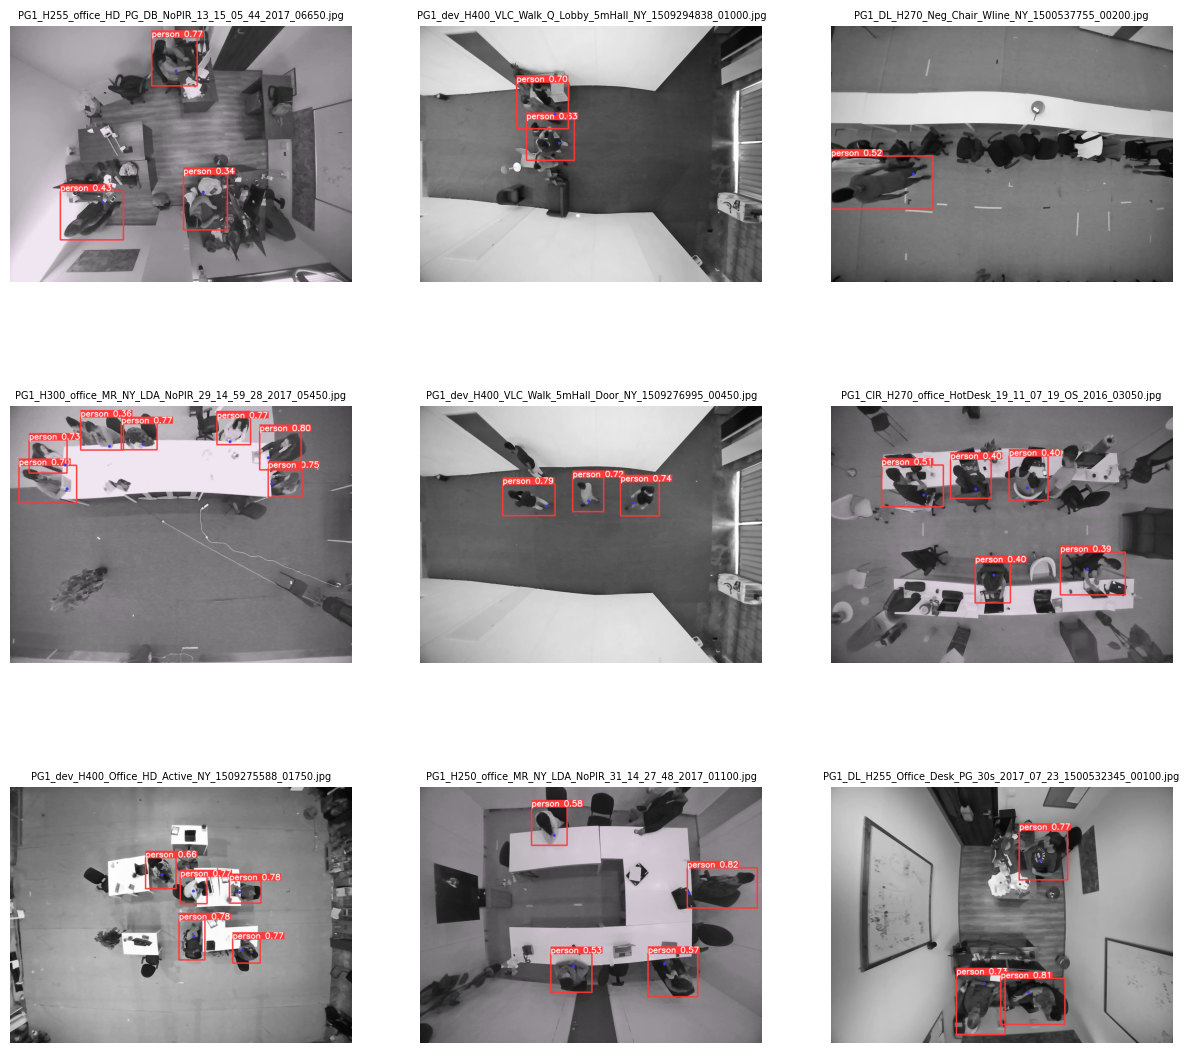

In [61]:
img_pths = glob.glob(os.path.join(HOLDOUT_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)